<a href="https://colab.research.google.com/github/safaelaafou29-cpu/MiniProjetCrypto/blob/main/Copie_de_Python_TD_1_SAFA_EL_AAFOU.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# ============================================
# TP : Puissance reçue et distance
# ============================================

# Partie 1 : Prise en main
import numpy as np
import matplotlib.pyplot as plt

print("Prêt :", np.__version__)

Prêt : 2.1.3


Distance : 1 km
Affaiblissement : 97.55 dB
Puissance reçue : -39.55 dBm

Distance : 2 km
Affaiblissement : 103.57 dB
Puissance reçue : -45.57 dBm

Distance : 5 km
Affaiblissement : 111.52 dB
Puissance reçue : -53.52 dBm

Distance : 10 km
Affaiblissement : 117.55 dB
Puissance reçue : -59.55 dBm



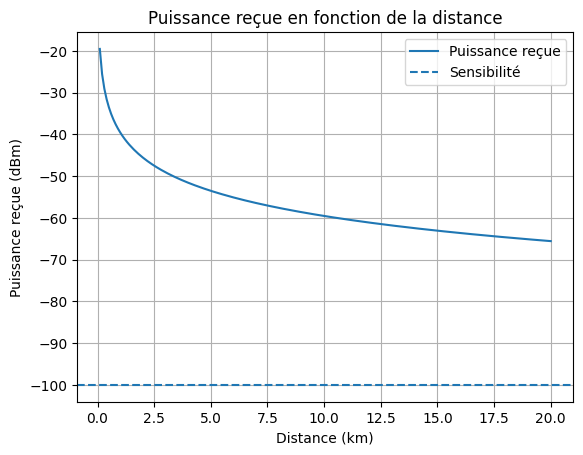

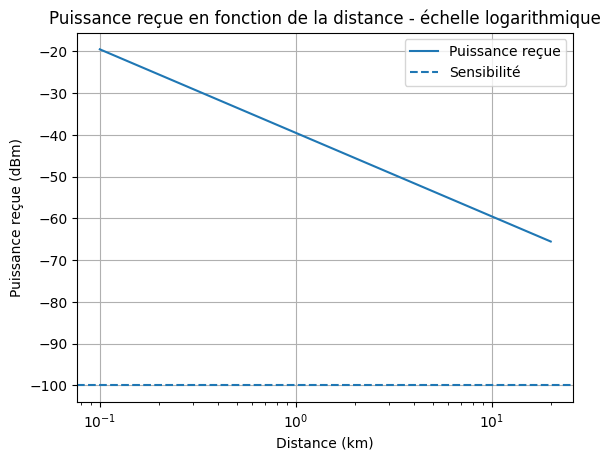

In [ ]:
# ============================================
# Données du TP
# ============================================

Pe = 43 # Puissance d'émission en dBm
Ge = 15 # Gain de l'antenne de la station de base en dB
Gr = 0 # Gain de l'antenne du téléphone en dB
f = 1800 # Fréquence en MHz
sens = -100 # Sensibilité du téléphone en dBm


# ============================================
# Partie 2 : Puissance reçue et distance
# ============================================

# b) Fonction d'affaiblissement en espace libre
def affaiblissement_espace_libre(d_km, f_mhz):
    L = 32.44 + 20 * np.log10(d_km) + 20 * np.log10(f_mhz)
    return L


# c) Fonction de puissance reçue
def puissance_recue(d_km, f_mhz):
    L = affaiblissement_espace_libre(d_km, f_mhz)
    Pr = Pe + Ge + Gr - L
    return Pr


# d) Afficher les résultats pour 1, 2, 5 et 10 km
distances_test = [1, 2, 5, 10]

for d in distances_test:
    L = affaiblissement_espace_libre(d, f)
    Pr = puissance_recue(d, f)

    print("Distance :", d, "km")
    print("Affaiblissement :", round(L, 2), "dB")
    print("Puissance reçue :", round(Pr, 2), "dBm")
    print()


# e) Tracer la puissance reçue de 0,1 à 20 km
distances = np.linspace(0.1, 20, 200)

puissances = [puissance_recue(d, f) for d in distances]

plt.plot(distances, puissances, label="Puissance reçue")
plt.axhline(sens, linestyle="--", label="Sensibilité")

plt.title("Puissance reçue en fonction de la distance")
plt.xlabel("Distance (km)")
plt.ylabel("Puissance reçue (dBm)")
plt.legend()
plt.grid()
plt.show()


# g) Tracer avec une échelle logarithmique
plt.plot(distances, puissances, label="Puissance reçue")
plt.axhline(sens, linestyle="--", label="Sensibilité")

plt.xscale("log")

plt.title("Puissance reçue en fonction de la distance - échelle logarithmique")
plt.xlabel("Distance (km)")
plt.ylabel("Puissance reçue (dBm)")
plt.legend()
plt.grid()
plt.show()

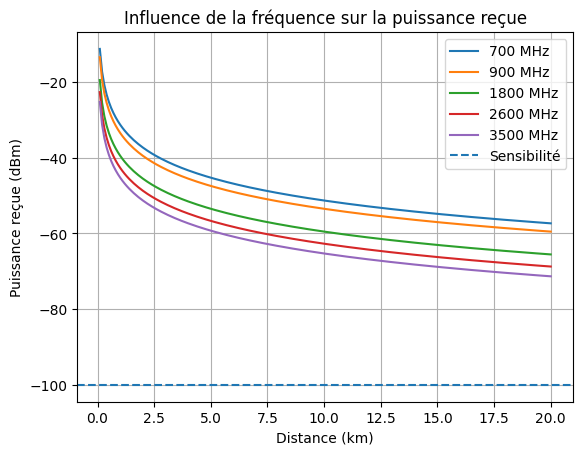

Puissance reçue à 2 km :
700 MHz : -37.36 dBm
900 MHz : -39.55 dBm
1800 MHz : -45.57 dBm
2600 MHz : -48.76 dBm
3500 MHz : -51.34 dBm

Comparaison à 2 km :
700 MHz -> -37.36 dBm
900 MHz -> -39.55 dBm
1800 MHz -> -45.57 dBm
2600 MHz -> -48.76 dBm
3500 MHz -> -51.34 dBm

Différence entre 900 MHz et 1800 MHz à 2 km :
6.02 dB


In [ ]:
# ============================================
# Partie 3 : Influence de la fréquence
# ============================================

# a) Liste des fréquences en MHz
frequences = [700, 900, 1800, 2600, 3500]


# b) Tracer la puissance reçue pour chaque fréquence
distances = np.linspace(0.1, 20, 200)

for frequence in frequences:
    puissances = [puissance_recue(d, frequence) for d in distances]
    plt.plot(distances, puissances, label=f"{frequence} MHz")

# Ligne de sensibilité
plt.axhline(sens, linestyle="--", label="Sensibilité")

plt.title("Influence de la fréquence sur la puissance reçue")
plt.xlabel("Distance (km)")
plt.ylabel("Puissance reçue (dBm)")
plt.legend()
plt.grid()
plt.show()


# c) Afficher la puissance reçue à 2 km
print("Puissance reçue à 2 km :")

for frequence in frequences:
    Pr = puissance_recue(2, frequence)
    print(f"{frequence} MHz : {Pr:.2f} dBm")


# ============================================
# Résultats pour 2 km
# ============================================

print()
print("Comparaison à 2 km :")

for frequence in frequences:
    Pr = puissance_recue(2, frequence)
    print(f"{frequence} MHz -> {Pr:.2f} dBm")


# ============================================
# e) Différence entre 900 MHz et 1800 MHz
# ============================================

Pr_900 = puissance_recue(2, 900)
Pr_1800 = puissance_recue(2, 1800)

difference = Pr_900 - Pr_1800

print()
print("Différence entre 900 MHz et 1800 MHz à 2 km :")
print(f"{difference:.2f} dB")

Budget de liaison : 158 dB

Portée sans pertes supplémentaires :
700 MHz : 2709.58 km
900 MHz : 2107.45 km
1800 MHz : 1053.73 km
2600 MHz : 729.50 km
3500 MHz : 541.92 km

Portée à 1800 MHz : 1053.73 km

Portée avec 30 dB de pertes supplémentaires :
700 MHz : 85.68 km
900 MHz : 66.64 km
1800 MHz : 33.32 km
2600 MHz : 23.07 km
3500 MHz : 17.14 km


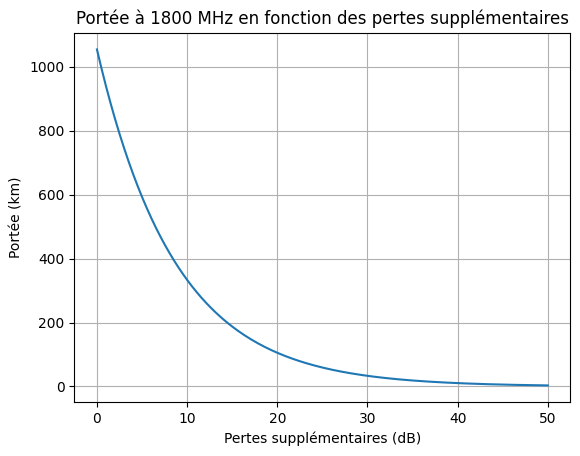


Portée sans pertes supplémentaires : 1053.73 km
Portée avec 20 dB de pertes : 105.37 km
La portée est divisée par : 10.0


In [ ]:
# ============================================
# Partie 4 : La portée
# ============================================

# a) Budget de liaison
budget = Pe + Ge + Gr - sens

print("Budget de liaison :", budget, "dB")


# b) Fonction qui calcule la portée
def portee(f_mhz, pertes_supp=0):
    # Les pertes supplémentaires sont retirées du budget
    budget_effectif = budget - pertes_supp

    # L'équation :
    # 32.44 + 20*log10(d) + 20*log10(f) = budget_effectif
    #
    # Donc :
    # d = 10^((budget_effectif - 32.44 - 20*log10(f)) / 20)

    d_km = 10 ** ((budget_effectif - 32.44 - 20 * np.log10(f_mhz)) / 20)

    return d_km


# c) Afficher la portée pour chaque fréquence
print()
print("Portée sans pertes supplémentaires :")

for frequence in frequences:
    d = portee(frequence)
    print(f"{frequence} MHz : {d:.2f} km")


# Portée à 1800 MHz
print()
print("Portée à 1800 MHz :", round(portee(1800), 2), "km")


# e) Portée avec 30 dB de pertes supplémentaires
print()
print("Portée avec 30 dB de pertes supplémentaires :")

for frequence in frequences:
    d = portee(frequence, pertes_supp=30)
    print(f"{frequence} MHz : {d:.2f} km")


# f) Portée à 1800 MHz en fonction des pertes supplémentaires
pertes = np.linspace(0, 50, 200)

portees = [portee(1800, pertes_supp=p) for p in pertes]

plt.plot(pertes, portees)

plt.title("Portée à 1800 MHz en fonction des pertes supplémentaires")
plt.xlabel("Pertes supplémentaires (dB)")
plt.ylabel("Portée (km)")
plt.grid()
plt.show()


# Calcul de la division de la portée avec 20 dB de pertes
portee_0 = portee(1800, pertes_supp=0)
portee_20 = portee(1800, pertes_supp=20)

division = portee_0 / portee_20

print()
print("Portée sans pertes supplémentaires :", round(portee_0, 2), "km")
print("Portée avec 20 dB de pertes :", round(portee_20, 2), "km")
print("La portée est divisée par :", round(division, 2))